<a href="https://colab.research.google.com/github/henryparfait/kinyarwanda-news-classifier/blob/main/notebooks/02_baselines.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Baselines: Classical Machine Learning

**Goal:** establish reference scores that every neural model must beat.

| Exp | Model | What changes | Why |
|---|---|---|---|
| B0 | Majority class | n/a | The floor: the score you get by always guessing the most common class |
| B1 | Word TF-IDF (1–2 grams) + Logistic Regression | n/a | Standard, strong text-classification baseline |
| B2 | Character TF-IDF (2–5 grams) + Logistic Regression | words → character n-grams | Kinyarwanda is agglutinative: one word packs many morphemes, so many word forms are rare. Character n-grams share information across forms of the same root |
| B3 | Best of B1/B2 + class-balanced weights | class weighting | Several categories have under 50 training examples, and weighting tests whether we can lift them |

Each experiment changes **one thing** compared with the previous one, so we know what caused any difference.
The regularisation strength `C` is chosen on the **validation** set. The test set is used only once per experiment.



## Step 1: Load the prepared data

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

import os, json, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

PROJECT_DIR = '/content/drive/MyDrive/kinyarwanda-news-classifier'
DATA_DIR, FIG_DIR = f'{PROJECT_DIR}/data', f'{PROJECT_DIR}/figures'
RESULTS_DIR, MODEL_DIR = f'{PROJECT_DIR}/results', f'{PROJECT_DIR}/models'
os.makedirs(MODEL_DIR, exist_ok=True)
LOG_PATH = f'{RESULTS_DIR}/experiment_log.csv'
SEED = 42

train = pd.read_csv(f'{DATA_DIR}/train.csv')
val   = pd.read_csv(f'{DATA_DIR}/val.csv')
test  = pd.read_csv(f'{DATA_DIR}/test_dedup.csv')   # primary test set
test_orig = pd.read_csv(f'{DATA_DIR}/test.csv')     # for comparison with the paper
id2name = {int(k): v for k, v in json.load(open(f'{DATA_DIR}/label_map.json'))['id2name'].items()}
LABELS = sorted(id2name)
NAMES = [id2name[i] for i in LABELS]
print(f'train {len(train)} | val {len(val)} | test_dedup {len(test)} | test_orig {len(test_orig)} | classes {len(LABELS)}')

Mounted at /content/drive
train 6726 | val 745 | test_dedup 3464 | test_orig 4254 | classes 14


## Step 2: Shared evaluation helpers
We report **macro-F1** as the main metric because it gives every category equal weight. With classes this imbalanced, accuracy is dominated by *politic*, *economy* and similar large classes and would hide failures on *tourism* or *fashion*. Accuracy and weighted-F1 are reported alongside it.

In [ ]:
from sklearn.metrics import (accuracy_score, precision_recall_fscore_support, f1_score,
                             classification_report, confusion_matrix, ConfusionMatrixDisplay)

def compute_metrics(y_true, y_pred):
    p, r, f, _ = precision_recall_fscore_support(y_true, y_pred, labels=LABELS,
                                                 average='macro', zero_division=0)
    return {'accuracy': accuracy_score(y_true, y_pred), 'macro_precision': p,
            'macro_recall': r, 'macro_f1': f,
            'weighted_f1': f1_score(y_true, y_pred, labels=LABELS, average='weighted', zero_division=0)}

def macro_f1(y_true, y_pred):
    return f1_score(y_true, y_pred, labels=LABELS, average='macro', zero_division=0)

def log_experiment(row):
    log = pd.read_csv(LOG_PATH)
    log = log[log['exp_id'] != row['exp_id']]          # re-running an experiment overwrites it
    log = pd.concat([log, pd.DataFrame([row])], ignore_index=True)
    log.to_csv(LOG_PATH, index=False)

def save_report(exp_id, y_true, y_pred):
    print(classification_report(y_true, y_pred, labels=LABELS, target_names=NAMES, digits=3, zero_division=0))
    rep = classification_report(y_true, y_pred, labels=LABELS, target_names=NAMES,
                                zero_division=0, output_dict=True)
    pd.DataFrame(rep).T.round(4).to_csv(f'{RESULTS_DIR}/{exp_id}_classification_report.csv')

def plot_cm(exp_id, y_true, y_pred, title):
    cm = confusion_matrix(y_true, y_pred, labels=LABELS, normalize='true')
    fig, ax = plt.subplots(figsize=(10, 9))
    ConfusionMatrixDisplay(cm, display_labels=NAMES).plot(ax=ax, cmap='Blues', values_format='.2f',
                                                          colorbar=False, xticks_rotation=45)
    ax.set_title(title); plt.tight_layout()
    plt.savefig(f'{FIG_DIR}/{exp_id}_confusion_matrix.png', dpi=200); plt.show()

## Step 3: Experiment runner
For each configuration we train one model per `C` value, keep the one with the best **validation** macro-F1, then evaluate it once on the test set.

In [ ]:
def run_sklearn(exp_id, model_name, make_pipe, grid, notes=''):
    t0, best = time.time(), None
    for params in grid:
        pipe = make_pipe(**params).fit(train['text'], train['label_id'])
        vf = macro_f1(val['label_id'], pipe.predict(val['text']))
        print(f'  {params} -> val macro-F1 = {vf:.4f}')
        if best is None or vf > best[0]:
            best = (vf, params, pipe)
    val_f1, params, pipe = best
    minutes = (time.time() - t0) / 60
    pred = pipe.predict(test['text'])
    m = compute_metrics(test['label_id'], pred)
    m_orig = compute_metrics(test_orig['label_id'], pipe.predict(test_orig['text']))
    log_experiment({'exp_id': exp_id, 'model': model_name, 'config': str(params),
                    'val_macro_f1': round(val_f1, 4), 'test_accuracy': round(m['accuracy'], 4),
                    'test_macro_f1': round(m['macro_f1'], 4), 'test_weighted_f1': round(m['weighted_f1'], 4),
                    'orig_test_macro_f1': round(m_orig['macro_f1'], 4),
                    'train_time_min': round(minutes, 2), 'notes': notes})
    print(f'{exp_id}: best {params} | val F1 {val_f1:.4f} | TEST acc {m["accuracy"]:.4f} '
          f'macro-F1 {m["macro_f1"]:.4f} weighted-F1 {m["weighted_f1"]:.4f} | {minutes:.1f} min')
    return pipe, pred, val_f1

## Step 4: B0, the majority-class floor

In [ ]:
from sklearn.dummy import DummyClassifier
dummy = DummyClassifier(strategy='most_frequent').fit(np.zeros((len(train), 1)), train['label_id'])
pred0 = dummy.predict(np.zeros((len(test), 1)))
m0 = compute_metrics(test['label_id'], pred0)
log_experiment({'exp_id': 'B0', 'model': 'Majority class', 'config': 'always predicts most frequent class',
                'val_macro_f1': round(macro_f1(val['label_id'], dummy.predict(np.zeros((len(val), 1)))), 4),
                'test_accuracy': round(m0['accuracy'], 4), 'test_macro_f1': round(m0['macro_f1'], 4),
                'test_weighted_f1': round(m0['weighted_f1'], 4), 'train_time_min': 0, 'notes': 'lower bound'})
print(m0)

{'accuracy': 0.09093533487297921, 'macro_precision': 0.006495381062355658, 'macro_recall': 0.07142857142857142, 'macro_f1': 0.011907912146070388, 'weighted_f1': 0.015159899700972982}


/tmp/ipykernel_8027/3971446977.py:17: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  log = pd.concat([log, pd.DataFrame([row])], ignore_index=True)


## Step 5: B1, word TF-IDF + Logistic Regression
Unigrams and bigrams, lower-cased, words must appear in at least 2 documents, and log-scaled term frequency (`sublinear_tf`) so very long articles don't dominate.

In [ ]:
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression

def word_vec():
    return TfidfVectorizer(lowercase=True, ngram_range=(1, 2), min_df=2, max_df=0.9,
                           sublinear_tf=True, max_features=200_000)
def char_vec():
    return TfidfVectorizer(lowercase=True, analyzer='char_wb', ngram_range=(2, 5), min_df=2,
                           sublinear_tf=True, max_features=300_000)

def make_lr(vec_fn, class_weight=None):
    def f(C):
        return Pipeline([('tfidf', vec_fn()),
                         ('clf', LogisticRegression(C=C, max_iter=3000, class_weight=class_weight))])
    return f

GRID = [{'C': 1.0}, {'C': 10.0}]
b1, pred_b1, vf_b1 = run_sklearn('B1', 'Word TF-IDF + LogReg', make_lr(word_vec), GRID,
                                 'word 1-2 grams')

  {'C': 1.0} -> val macro-F1 = 0.4292
  {'C': 10.0} -> val macro-F1 = 0.5528
B1: best {'C': 10.0} | val F1 0.5528 | TEST acc 0.6911 macro-F1 0.4133 weighted-F1 0.6555 | 3.7 min


## Step 6: B2, character TF-IDF + Logistic Regression

In [ ]:
b2, pred_b2, vf_b2 = run_sklearn('B2', 'Char TF-IDF + LogReg', make_lr(char_vec), GRID,
                                 'char_wb 2-5 grams')

  {'C': 1.0} -> val macro-F1 = 0.4761
  {'C': 10.0} -> val macro-F1 = 0.6231
B2: best {'C': 10.0} | val F1 0.6231 | TEST acc 0.7099 macro-F1 0.4584 weighted-F1 0.6812 | 7.5 min


## Step 7: B3, best features + class-balanced weights
`class_weight='balanced'` makes mistakes on rare classes cost more during training.

In [ ]:
best_vec, best_name = (word_vec, 'Word') if vf_b1 >= vf_b2 else (char_vec, 'Char')
print('Using', best_name, 'features (higher validation macro-F1)')
b3, pred_b3, vf_b3 = run_sklearn('B3', f'{best_name} TF-IDF + LogReg (balanced)',
                                 make_lr(best_vec, class_weight='balanced'), GRID,
                                 f'{best_name.lower()} features, class_weight=balanced')

Using Char features (higher validation macro-F1)
  {'C': 1.0} -> val macro-F1 = 0.7451
  {'C': 10.0} -> val macro-F1 = 0.6862
B3: best {'C': 1.0} | val F1 0.7451 | TEST acc 0.7428 macro-F1 0.5773 weighted-F1 0.7421 | 5.2 min


## Step 8: Detailed results for the best baseline
The best baseline is chosen by **validation** score (not test score). This is the model the neural networks have to beat.

Best baseline: B3
               precision    recall  f1-score   support

      politic      0.648     0.603     0.625       315
        sport      0.957     0.935     0.946       744
      economy      0.479     0.667     0.558       174
       health      0.625     0.691     0.656       272
entertainment      0.846     0.822     0.834       774
      history      0.068     0.818     0.126        11
   technology      0.557     0.854     0.674       103
      tourism      0.784     0.382     0.513        76
      culture      0.717     0.312     0.434       138
      fashion      0.868     0.505     0.639        91
     religion      0.843     0.711     0.771       256
  environment      0.889     0.240     0.378       100
    education      0.227     0.071     0.109        70
 relationship      0.723     0.944     0.819       340

     accuracy                          0.743      3464
    macro avg      0.659     0.611     0.577      3464
 weighted avg      0.775     0.743     0.742 

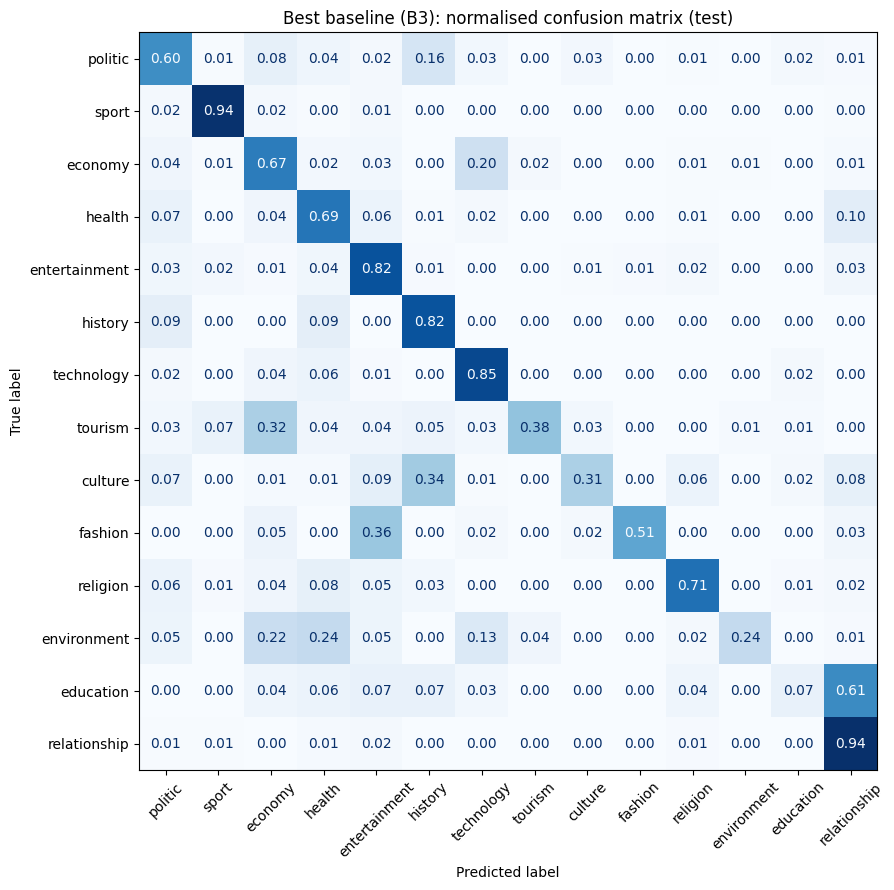

In [ ]:
import joblib
cands = {'B1': (b1, pred_b1, vf_b1), 'B2': (b2, pred_b2, vf_b2), 'B3': (b3, pred_b3, vf_b3)}
best_id = max(cands, key=lambda k: cands[k][2])
best_pipe, best_pred, _ = cands[best_id]
print('Best baseline:', best_id)

save_report(f'{best_id}_best_baseline', test['label_id'], best_pred)
plot_cm(f'{best_id}_best_baseline', test['label_id'], best_pred,
        f'Best baseline ({best_id}): normalised confusion matrix (test)')

joblib.dump(best_pipe, f'{MODEL_DIR}/best_baseline.joblib')
pd.DataFrame({'text': test['text'], 'true': test['label_id'].map(id2name),
              'pred': pd.Series(best_pred).map(id2name).values}).to_csv(
    f'{RESULTS_DIR}/best_baseline_test_predictions.csv', index=False)

## Step 9: What does the word model actually look at?
The highest-weighted words for each category show what the model relies on.

In [ ]:
vec, clf = b1.named_steps['tfidf'], b1.named_steps['clf']
feats = np.array(vec.get_feature_names_out())
rows = []
for i in LABELS:
    top = feats[np.argsort(clf.coef_[i])[-12:][::-1]]
    rows.append({'category': id2name[i], 'top_features': ', '.join(top)})
top_df = pd.DataFrame(rows)
top_df.to_csv(f'{RESULTS_DIR}/B1_top_features.csv', index=False)
pd.set_option('display.max_colwidth', 200)
top_df

,category,top_features
0,politic,"umutekano, perezida, 2019, kagame, rib, perezida kagame, leta, igihugu, rwanda, abaturage, ingabo, gen"
1,sport,"ikipe, umukino, abakinnyi, mukino, imikino, amakipe, sports, ikipe ya, rayon, shampiyona, fc, kipe"
2,economy,"yanditswe, yanditswe na, amafaranga, banki, imari, muhabura rw, iterambere, muhabura, ubukungu, ubuhinzi, rwandair, ubucuruzi"
3,health,"ubuzima, muhabura rw, muhabura, minisiteri ubuzima, bitaro, ebola, yanditswe na, dr, abaganga, yanditswe, coronavirus, indwara"
4,entertainment,"umuhanzi, indirimbo, filime, umuziki, nyampinga, muhanzi, abahanzi, miss, bahanzi, uyu muhanzi, muzika, diamond"
5,history,"abatutsi, amateka, jenoside, ingabo, umwami, views, test, intambara, abahutu, mateka, yari, hitler"
6,technology,"ikoranabuhanga, kompanyi, internet, mudasobwa, indege, telefone, ikoranabuhanga mu, za, amerika, ndege, gukoresha, apple"
7,tourism,"pariki, rdb, parike, nyungwe, rwigamba, inyamaswa, intyoza com, intyoza, ingagi, rica rwigamba, ubukerarugendo, rica"
8,culture,"umuco, umwami, inka, nyarwanda, abanyarwanda, bati, umuco nyarwanda, kigeli, kinyarwanda, nâ, gakondo, wâ"
9,fashion,"miss, imideri, fashion, miss rwanda, imideli, ubukwe, rya miss, bombi, bakoze ubukwe, fashion week, kumurika, imideri mu"


## Step 10: Experiment log so far

In [ ]:
pd.read_csv(LOG_PATH)

,exp_id,model,config,val_macro_f1,test_accuracy,test_macro_f1,test_weighted_f1,train_time_min,notes,orig_test_macro_f1
0,B0,Majority class,always predicts most frequent class,0.0273,0.0909,0.0119,0.0152,0.00,lower bound,NaN
1,B1,Word TF-IDF + LogReg,{'C': 10.0},0.5528,0.6911,0.4133,0.6555,3.71,word 1-2 grams,0.4062
2,B2,Char TF-IDF + LogReg,{'C': 10.0},0.6231,0.7099,0.4584,0.6812,7.50,char_wb 2-5 grams,0.4514
3,B3,Char TF-IDF + LogReg (balanced),{'C': 1.0},0.7451,0.7428,0.5773,0.7421,5.23,"char features, class_weight=balanced",0.5759
